# HW2 — YOLO11s Anchor-free, 1280 px (Kaggle)

**Мета:** виконати пункт *One-stage Anchor-free* за єдиним протоколом на 3 `GroupKFold`-фолдах, порівняти початкову й налаштовану YOLO11s, отримати AP за розмірами об'єктів і сформувати Kaggle submission.

## План з урахуванням ліміту часу
- Модель: `yolo11s.pt`.
- Роздільність для обох експериментів: **1280**.
- 3 фолди; `epochs=12`, `patience=6`, `batch=8`.
- Початкова конфігурація: `box=7.5`, `mosaic=1.0`.
- Налаштована: `box=10.0`, `mosaic=0.7`.
- Тобто перевіряються два параметри: вага box-loss і сила Mosaic augmentation. Для чистого порівняння дані, фолди, resolution і seed однакові.

Це план на 6 запусків (2 конфігурації × 3 фолди), а не гарантія вкластися в 16 годин: фактичний час залежить від GPU та розміру датасету. Після першого фолду перевір фактичний час; якщо він завеликий, скороти кількість фолдів або епох.

## Перед стартом
1. У Kaggle натисни **Add Input** і додай датасет змагання.
2. В Settings → Accelerator вибери GPU.
3. Якщо доступний лише один T4 — використовуємо його (`device=0`).
4. Увімкни Internet для завантаження `yolo11s.pt`.
5. Запускай клітинки послідовно. Не переривай сесію під час запису ваг.

Всі результати, checkpoints і CSV будуть у `/kaggle/working/`. Після завершення натисни **Save Version**.

In [1]:
# 1. Залежності та імпорти
!pip -q install ultralytics==8.4.201 pycocotools

import os, json, time, gc, math, random, shutil, contextlib, io
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image

from sklearn.model_selection import GroupKFold
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from ultralytics import YOLO, settings

settings.update({"wandb": False})
assert torch.cuda.is_available(), "Увімкни GPU у Settings → Accelerator."
print("Ultralytics:", __import__("ultralytics").__version__)
print("GPU:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics: 8.4.201
GPU: Tesla T4


In [2]:
# 2. Знайти датасет, доданий через Kaggle Add Input
INPUT_ROOT = Path("/kaggle/input")
hits = []
for p in INPUT_ROOT.rglob("annotations_coco.json"):
    if p.parent.name in ("train", "val"):
        root = p.parent.parent
        if ((root / "train" / "annotations_coco.json").exists()
            and (root / "val" / "annotations_coco.json").exists()
            and (root / "test_images.csv").exists()):
            hits.append(root)

if not hits:
    print("Доступні inputs:")
    for p in INPUT_ROOT.iterdir():
        print(" -", p)
    raise FileNotFoundError(
        "Не знайдено train/annotations_coco.json, val/annotations_coco.json і test_images.csv. "
        "Додай competition dataset через Add Input."
    )

DATA = hits[0]
print("Dataset:", DATA)
print("Test metadata:", DATA / "test_images.csv")

Dataset: /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026
Test metadata: /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026/test_images.csv


In [3]:
# 3. Конфігурація — можна зменшити EPOCHS після першого фолду, якщо час обмежений
SEED = 42
STEP = 4
N_FOLDS = 3
RUN_FOLDS = [0, 1, 2]

IMGSZ = 1280
EPOCHS = 12
PATIENCE = 6
BATCH = 8
WORKERS = 2
SAVE_MAX = 1600
INNER_VAL = 500

MAX_DET = 500
VAL_CONF = 0.001
NMS_IOU = 0.6
CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]

MODEL_WEIGHTS = "yolo11s.pt"
EXPERIMENTS = {
    "Y11_1280_initial": {"box": 7.5, "mosaic": 1.0},
    "Y11_1280_tuned":   {"box": 10.0, "mosaic": 0.7},
}

OUT = Path("/kaggle/working")
WORK = OUT / "yolo11_1280_data"
RUNS = OUT / "yolo11_1280_runs"
WEIGHTS_OUT = OUT / "yolo11_1280_weights"
RESULTS = OUT / "yolo11_1280_results"
for d in (WORK, RUNS, WEIGHTS_OUT, RESULTS):
    d.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Image size:", IMGSZ, "| epochs:", EPOCHS, "| folds:", RUN_FOLDS)
print("Experiment grid:", EXPERIMENTS)

Image size: 1280 | epochs: 12 | folds: [0, 1, 2]
Experiment grid: {'Y11_1280_initial': {'box': 7.5, 'mosaic': 1.0}, 'Y11_1280_tuned': {'box': 10.0, 'mosaic': 0.7}}


## 1. Протокол даних і фолди

Об'єднуємо train/val метадані, але розбиваємо за `video` через `GroupKFold`: кадри одного кліпу не потрапляють одночасно в train і OOF validation. Беремо кожен 4-й кадр, як у початковому pipeline. `iscrowd=1` регіони виключаються з оцінки та маскуються на зображеннях.

In [4]:
# 4. Прочитати COCO annotations і створити GroupKFold
OFF = {"train": 0, "val": 10**7}

def load_split(split):
    with open(DATA / split / "annotations_coco.json", "r") as f:
        coco = json.load(f)

    imgs = pd.DataFrame(coco["images"]).rename(columns={"id": "image_id"})
    imgs["path"] = [
        str(DATA / split / "images" / str(v) / Path(fname).name)
        for v, fname in zip(imgs["video"], imgs["file_name"])
    ]
    imgs["split"] = split
    imgs["image_id"] = imgs["image_id"] + OFF[split]

    ann = pd.DataFrame(coco["annotations"]).copy()
    ann["image_id"] = ann["image_id"] + OFF[split]
    ann[["x", "y", "w", "h"]] = pd.DataFrame(ann["bbox"].tolist(), index=ann.index)
    ann["cls"] = ann["category_id"] - 1
    ann = ann.merge(
        imgs[["image_id", "video", "frame_id", "width", "height"]],
        on="image_id"
    )
    target = ann[ann["iscrowd"] == 0].drop(columns=["bbox"]).reset_index(drop=True)
    ignored = ann[ann["iscrowd"] == 1].drop(columns=["bbox"]).reset_index(drop=True)
    return imgs, target, ignored

T = {s: load_split(s) for s in OFF}
imgs_all = pd.concat([T[s][0] for s in OFF], ignore_index=True)
obj_all = pd.concat([T[s][1] for s in OFF], ignore_index=True)
ign_all = pd.concat([T[s][2] for s in OFF], ignore_index=True)

assert not (set(T["train"][0].video) & set(T["val"][0].video)), "Train/val video clips overlap!"

OBJ_BY_IMG = {k: g for k, g in obj_all.groupby("image_id")}
IGN_BY_IMG = {k: g[["x", "y", "w", "h"]].values for k, g in ign_all.groupby("image_id")}

fold_of = {}
for k, (_, te) in enumerate(
    GroupKFold(n_splits=N_FOLDS).split(imgs_all, groups=imgs_all.video)
):
    fold_of.update({v: k for v in imgs_all.video.iloc[te].unique()})

FR = imgs_all.sort_values(["video", "frame_id"]).copy()
FR = FR[FR.groupby("video").cumcount() % STEP == 0].copy()
FR["fold"] = FR.video.map(fold_of)
FR = FR.reset_index(drop=True)

TRAIN = lambda k: FR[FR.fold != k]
VAL = lambda k: FR[FR.fold == k]
VSUB = lambda k: VAL(k).sample(min(INNER_VAL, len(VAL(k))), random_state=SEED)

print(FR.groupby("fold").agg(clips=("video", "nunique"), frames=("image_id", "size")))
print("Total sampled frames:", len(FR))

      clips  frames
fold               
0        21    2263
1        21    2265
2        21    2258
Total sampled frames: 6786


In [5]:
# 5. Підготувати зображення та YOLO labels
def prep_all(root):
    root = Path(root)

    def one(r):
        img_path = root / "images" / r.video / Path(r.path).name
        label_path = root / "labels" / r.video / (img_path.stem + ".txt")

        if img_path.exists() and label_path.exists():
            return

        img_path.parent.mkdir(parents=True, exist_ok=True)
        label_path.parent.mkdir(parents=True, exist_ok=True)

        g = OBJ_BY_IMG.get(r.image_id)
        labels = []
        if g is not None and len(g):
            b = np.clip(
                np.c_[g.x, g.y, g.x + g.w, g.y + g.h],
                0, [r.width, r.height] * 2
            )
            valid = (b[:, 2] > b[:, 0]) & (b[:, 3] > b[:, 1])
            labels = [
                f"{int(c)} {(x1+x2)/2/r.width:.6f} {(y1+y2)/2/r.height:.6f} "
                f"{(x2-x1)/r.width:.6f} {(y2-y1)/r.height:.6f}"
                for c, (x1, y1, x2, y2) in zip(g.cls.values[valid], b[valid])
            ]
        label_path.write_text("\n".join(labels))

        im = Image.open(r.path).convert("RGB")
        arr = np.array(im)
        for x, y, w, h in IGN_BY_IMG.get(r.image_id, []):
            x1 = max(0, int(x)); y1 = max(0, int(y))
            x2 = min(arr.shape[1], int(np.ceil(x + w)))
            y2 = min(arr.shape[0], int(np.ceil(y + h)))
            if x2 > x1 and y2 > y1:
                arr[y1:y2, x1:x2] = 114
        im = Image.fromarray(arr)
        im.thumbnail((SAVE_MAX, SAVE_MAX))
        im.save(img_path, quality=95)

    with ThreadPoolExecutor(max_workers=8) as ex:
        list(ex.map(one, list(FR.itertuples(index=False))))
    print("Prepared", len(FR), "frames in", root)

def fold_yaml(k):
    for name, df in [("train", TRAIN(k)), ("val", VSUB(k))]:
        (WORK / f"fold{k}_{name}.txt").write_text("\n".join(
            str(WORK / "images" / r.video / Path(r.path).name)
            for r in df.itertuples(index=False)
        ))

    y = WORK / f"data_fold{k}.yaml"
    y.write_text(
        f"path: {WORK}\n"
        f"train: {WORK / f'fold{k}_train.txt'}\n"
        f"val: {WORK / f'fold{k}_val.txt'}\n"
        f"names: {dict(enumerate(CLASSES))}\n"
    )
    return y

prep_all(WORK)

Prepared 6786 frames in /kaggle/working/yolo11_1280_data


In [7]:
# 6. COCO OOF evaluation: mAP та AP за розміром об'єкта
_GT = None

def get_gt():
    global _GT
    if _GT is None:
        o = obj_all[obj_all.image_id.isin(FR.image_id)]
        dataset = {
            "images": [
                {"id": int(i), "width": int(w), "height": int(h)}
                for i, w, h in zip(FR.image_id, FR.width, FR.height)
            ],
            "annotations": [
                {
                    "id": n + 1, "image_id": int(i), "category_id": int(c) + 1,
                    "bbox": [float(x), float(y), float(w), float(h)],
                    "area": float(w * h), "iscrowd": 0
                }
                for n, (i, c, x, y, w, h) in enumerate(
                    zip(o.image_id, o.cls, o.x, o.y, o.w, o.h)
                )
            ],
            "categories": [
                {"id": i + 1, "name": name} for i, name in enumerate(CLASSES)
            ]
        }
        cg = COCO()
        cg.dataset = dataset
        with contextlib.redirect_stdout(io.StringIO()):
            cg.createIndex()
        _GT = cg
    return _GT

def drop_ignored(xyxy, scores, labels, ign, thr=0.5):
    if len(xyxy) == 0 or len(ign) == 0:
        return xyxy, scores, labels
    gx1, gy1 = ign[:, 0], ign[:, 1]
    gx2, gy2 = ign[:, 0] + ign[:, 2], ign[:, 1] + ign[:, 3]
    ix = (np.minimum(xyxy[:, None, 2], gx2) - np.maximum(xyxy[:, None, 0], gx1)).clip(0)
    iy = (np.minimum(xyxy[:, None, 3], gy2) - np.maximum(xyxy[:, None, 1], gy1)).clip(0)
    area = ((xyxy[:, 2] - xyxy[:, 0]) * (xyxy[:, 3] - xyxy[:, 1])).clip(1e-6)
    keep = (ix * iy).sum(1) / area < thr
    return xyxy[keep], scores[keep], labels[keep]

def coco_eval(preds, frame_df, ms_per_img=float("nan")):
    rows = []
    for iid, path in zip(frame_df.image_id, frame_df.path):
        xyxy, scores, labels = preds[str(Path(path))]
        xyxy, scores, labels = drop_ignored(
            xyxy, scores, labels, IGN_BY_IMG.get(iid, np.zeros((0, 4)))
        )
        if len(scores):
            rows.append(np.c_[
                np.full(len(scores), iid),
                xyxy[:, 0], xyxy[:, 1],
                xyxy[:, 2] - xyxy[:, 0], xyxy[:, 3] - xyxy[:, 1],
                scores, labels + 1
            ])

    dets = np.concatenate(rows).astype(np.float64) if rows else np.zeros((0, 7))
    gt = get_gt()
    with contextlib.redirect_stdout(io.StringIO()):
        if len(dets):
            dt = gt.loadRes(dets)
        else:
            dt = COCO()
            dt.dataset = {
                "images": gt.dataset["images"],
                "categories": gt.dataset["categories"],
                "annotations": []
            }
            dt.createIndex()

        ev = COCOeval(gt, dt, "bbox")
        ev.params.imgIds = [int(i) for i in frame_df.image_id]
        ev.params.maxDets = [1, 10, MAX_DET]
        ev.evaluate(); ev.accumulate(); ev.summarize()

    P = ev.eval["precision"]
    def ap(area=0, iou=None):
        p = P[:, :, :, area, 2] if iou is None else P[
            [int(np.argmin(abs(ev.params.iouThrs - iou)))], :, :, area, 2
        ]
        return float(p[p > -1].mean()) if (p > -1).any() else float("nan")

    return {
        "mAP": ap(), "AP50": ap(iou=0.5),
        "AP_small": ap(1), "AP_medium": ap(2), "AP_large": ap(3),
        "ms_per_img": float(ms_per_img)
    }

def predict_fn(model, paths, imgsz=IMGSZ, conf=VAL_CONF, batch=4):
    out, total_ms = {}, 0.0
    for start in range(0, len(paths), batch):
        results = model.predict(
            paths[start:start + batch],
            imgsz=imgsz, conf=conf, iou=NMS_IOU,
            max_det=MAX_DET, half=True, device=0, verbose=False
        )
        for r in results:
            b = r.boxes
            out[str(Path(r.path))] = (
                b.xyxy.cpu().numpy(),
                b.conf.cpu().numpy(),
                b.cls.cpu().numpy().astype(int)
            )
            total_ms += sum(r.speed.values())
    return out, total_ms / max(len(paths), 1)

def evaluate_model(model, frame_df):
    preds, ms = predict_fn(model, [str(p) for p in frame_df.path])
    metrics = coco_eval(preds, frame_df, ms)
    del preds
    gc.collect()
    torch.cuda.empty_cache()
    return metrics

## 2. Anchor-free: як YOLO11 призначає об'єкти

YOLO11 не використовує набір заздалегідь заданих anchor-box розмірів і пропорцій. Детекційна голова прогнозує класи та координати від **точок сітки** на кількох рівнях feature pyramid. Під час навчання Task-Aligned Assigner вибирає позитивні точки всередині GT-боксу, ранжує кандидатів за метрикою, що поєднує classification score та IoU, і розв'язує конфлікти, коли кандидат підходить кільком GT.

- **Малі об'єкти:** на вищій роздільності 1280 вони займають більше пікселів і можуть охоплювати більше точок сітки, що може покращити локалізацію. Проте дуже малі об'єкти все одно можуть мати мало позитивних кандидатів.
- **Щільні сцени:** кілька близьких GT можуть конкурувати за одні й ті самі точки; assigner мусить розв'язувати конфлікти. Відсутність anchors зменшує залежність від заздалегідь заданих розмірів, але сама по собі не усуває перекриття об'єктів.

Для звіту: YOLO11 використовує anchor-free decoupled Detect head і Task-Aligned Assigner; box regression містить CIoU та DFL. `box` змінює вагу box-loss, а не замінює її математичну форму. Джерела: [архітектура YOLO](https://docs.ultralytics.com/guides/yolo-architecture) та [TaskAlignedAssigner](https://docs.ultralytics.com/reference/utils/tal).

In [8]:
# 7. Навчання двох конфігурацій на однакових 3 фолдах
def metrics_file(exp, k):
    return RESULTS / f"{exp}_f{k}.json"

def weight_file(exp, k):
    return RUNS / f"{exp}_f{k}" / "weights" / "best.pt"

def train_one(exp, k, cfg):
    mf = metrics_file(exp, k)
    wf = weight_file(exp, k)
    run_name = f"{exp}_f{k}"
    run_dir = RUNS / run_name
    last = run_dir / "weights" / "last.pt"

    if mf.exists() and wf.exists():
        print("Already completed:", run_name)
        return json.load(open(mf))["metrics"]

    data_yaml = fold_yaml(k)

    if not wf.exists():
        if last.exists():
            print("Found last.pt; attempting resume:", run_name)
            model = YOLO(str(last))
            model.train(resume=True)
        else:
            model = YOLO(MODEL_WEIGHTS)
            model.train(
                data=str(data_yaml),
                imgsz=IMGSZ,
                epochs=EPOCHS,
                batch=BATCH,
                device=0,
                workers=WORKERS,
                seed=SEED,
                optimizer="auto",
                box=cfg["box"],
                mosaic=cfg["mosaic"],
                close_mosaic=5,
                patience=PATIENCE,
                amp=True,
                plots=True,
                project=str(RUNS),
                name=run_name,
                exist_ok=True,
                cache=False,
                save=True,
                val=True
            )
        del model
        gc.collect()
        torch.cuda.empty_cache()

    if not wf.exists():
        raise FileNotFoundError(f"best.pt not found: {wf}")

    # OOF оцінка на повному held-out fold, не на внутрішній підвибірці Ultralytics.
    model = YOLO(str(wf))
    metrics = evaluate_model(model, VAL(k))
    del model
    gc.collect()
    torch.cuda.empty_cache()

    copied = WEIGHTS_OUT / f"{exp}_fold{k}_best.pt"
    shutil.copy2(wf, copied)

    payload = {
        "metrics": metrics,
        "cfg": {
            "model": MODEL_WEIGHTS, "imgsz": IMGSZ, "epochs": EPOCHS,
            "batch": BATCH, "fold": k, "seed": SEED, **cfg
        },
        "weights": str(copied)
    }
    with open(mf, "w") as f:
        json.dump(payload, f, indent=2)

    print(run_name, {a: round(float(b), 4) for a, b in metrics.items()})
    return metrics

started = time.time()
all_metrics = {}
for exp, cfg in EXPERIMENTS.items():
    all_metrics[exp] = {}
    for k in RUN_FOLDS:
        all_metrics[exp][k] = train_one(exp, k, cfg)
    elapsed = (time.time() - started) / 3600
    print(f"Elapsed so far: {elapsed:.2f} hours")
print("Training/evaluation loop finished.")

New https://pypi.org/project/ultralytics/8.4.208 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.201 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/yolo11_1280_data/data_fold0.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=12, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yo

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/12      10.8G      1.504     0.8983      1.067        285       1280: 100% ━━━━━━━━━━━━ 566/566 2.4it/s 3:590.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 3.8it/s 8.4s0.3s
                   all        500      24857      0.478      0.398      0.377      0.196

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/12      12.4G      1.469      0.845      1.057        380       1280: 100% ━━━━━━━━━━━━ 566/566 2.4it/s 3:590.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 32/32 3.8it/s 8.5s0.3s
                   all        500      24857      0.496      0.406      0.379      0.192

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/12      12.5G      1.426     0.7997      1.041        354       1280: 100% ━━━━━━━━━━━━ 566/566 2.4it/s 3:580.3ss
                 Class     Images

In [9]:
# 8. Звести OOF-метрики по фолдах і вибрати конфігурацію
rows = []
for exp in EXPERIMENTS:
    for k in RUN_FOLDS:
        f = metrics_file(exp, k)
        if f.exists():
            rows.append({"experiment": exp, "fold": k, **json.load(open(f))["metrics"]})

fold_table = pd.DataFrame(rows)
display(fold_table.round(4))

summary = (
    fold_table.groupby("experiment")[["mAP", "AP50", "AP_small", "AP_medium", "AP_large", "ms_per_img"]]
    .mean().round(4)
)
summary["mAP_std"] = fold_table.groupby("experiment")["mAP"].std().round(4)
display(summary.sort_values("mAP", ascending=False))

best_exp = summary["mAP"].idxmax()
print("Selected by mean OOF mAP:", best_exp)
summary.to_csv(OUT / "yolo11_1280_oof_summary.csv")
fold_table.to_csv(OUT / "yolo11_1280_oof_by_fold.csv", index=False)

,experiment,fold,mAP,AP50,AP_small,AP_medium,AP_large,ms_per_img
0,Y11_1280_initial,0,0.1928,0.3734,0.1038,0.1750,0.3654,15.9744
1,Y11_1280_initial,1,0.1836,0.3560,0.0942,0.1822,0.3217,15.9841
2,Y11_1280_initial,2,0.2226,0.4326,0.0834,0.2198,0.3624,17.7635
3,Y11_1280_tuned,0,0.1850,0.3542,0.0934,0.1592,0.3484,15.5359
4,Y11_1280_tuned,1,0.1902,0.3680,0.0800,0.1822,0.3202,16.4737
5,Y11_1280_tuned,2,0.2085,0.4036,0.0791,0.2112,0.3498,17.5719


,mAP,AP50,AP_small,AP_medium,AP_large,ms_per_img,mAP_std
experiment,,,,,,,
Y11_1280_initial,0.1997,0.3873,0.0938,0.1924,0.3499,16.5740,0.0204
Y11_1280_tuned,0.1946,0.3752,0.0842,0.1842,0.3395,16.5272,0.0124


Selected by mean OOF mAP: Y11_1280_initial


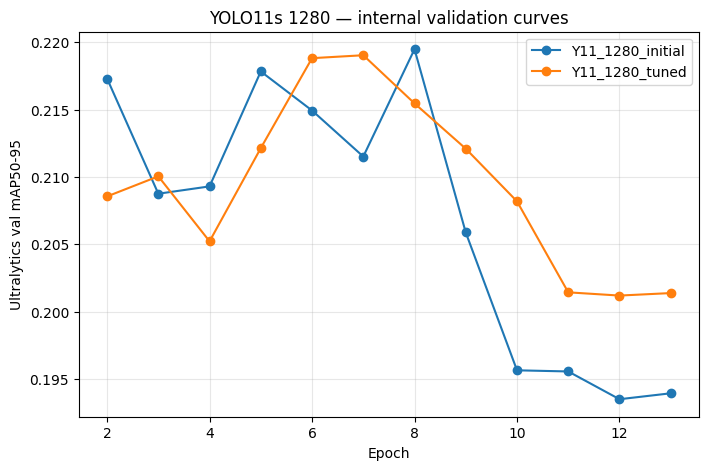

Training time per fold (hours):
Y11_1280_initial fold 0 0.68
Y11_1280_initial fold 1 0.82
Y11_1280_initial fold 2 0.49
Y11_1280_tuned fold 0 0.81
Y11_1280_tuned fold 1 0.81
Y11_1280_tuned fold 2 0.55


In [10]:
# 9. Крива навчання та час для кожної конфігурації
fig, ax = plt.subplots(figsize=(8, 5))
for exp in EXPERIMENTS:
    dfs = []
    for k in RUN_FOLDS:
        f = RUNS / f"{exp}_f{k}" / "results.csv"
        if f.exists():
            d = pd.read_csv(f)
            d.columns = [x.strip() for x in d.columns]
            dfs.append(d)
    if dfs:
        curve = pd.concat(dfs).groupby("epoch").mean(numeric_only=True)
        if "metrics/mAP50-95(B)" in curve:
            ax.plot(curve.index + 1, curve["metrics/mAP50-95(B)"], marker="o", label=exp)
ax.set_xlabel("Epoch")
ax.set_ylabel("Ultralytics val mAP50-95")
ax.set_title("YOLO11s 1280 — internal validation curves")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

print("Training time per fold (hours):")
for exp in EXPERIMENTS:
    for k in RUN_FOLDS:
        f = RUNS / f"{exp}_f{k}" / "results.csv"
        if f.exists():
            d = pd.read_csv(f)
            d.columns = [x.strip() for x in d.columns]
            if "time" in d:
                print(exp, "fold", k, round(float(d.time.iloc[-1]) / 3600, 2))

## 3. Порівняння з anchor-based моделями

`AP_small`, `AP_medium`, `AP_large` у таблиці вище — основний розподіл за розміром об'єкта. Щоб заповнити порівняння з Faster R-CNN / RetinaNet із ноутбука №1, завантаж у Kaggle як окремий Input CSV `anchor_based_metrics.csv` з колонками:

`model,mAP,AP_small,AP_medium,AP_large`

Один рядок на кожен anchor-based експеримент. Не вигадуй значення: якщо файл не додано, клітинка нижче збере шаблон для заповнення. Порівнюй на однакових OOF-фолдах/метриці, якщо це можливо.

In [11]:
# 10. Таблиця для звіту: YOLO11 initial/tuned + опційні anchor-based результати
yolo_report = summary.reset_index().rename(columns={"experiment": "model"})
template = pd.DataFrame([
    {"model": "Faster R-CNN tuned", "mAP": np.nan, "AP_small": np.nan, "AP_medium": np.nan, "AP_large": np.nan},
    {"model": "RetinaNet tuned", "mAP": np.nan, "AP_small": np.nan, "AP_medium": np.nan, "AP_large": np.nan},
])
anchor_files = list(Path("/kaggle/input").rglob("anchor_based_metrics.csv"))
if anchor_files:
    anchor = pd.read_csv(anchor_files[0])
    report = pd.concat([yolo_report, anchor], ignore_index=True, sort=False)
    print("Loaded anchor-based results:", anchor_files[0])
else:
    report = pd.concat([yolo_report, template], ignore_index=True, sort=False)
    print("No anchor_based_metrics.csv found. Fill the two anchor-based rows with results from Notebook 1.")

cols = ["model", "mAP", "AP_small", "AP_medium", "AP_large"]
display(report[[c for c in cols if c in report.columns]].round(4))
report.to_csv(OUT / "anchor_free_vs_anchor_based_report.csv", index=False)

No anchor_based_metrics.csv found. Fill the two anchor-based rows with results from Notebook 1.


,model,mAP,AP_small,AP_medium,AP_large
0,Y11_1280_initial,0.1997,0.0938,0.1924,0.3499
1,Y11_1280_tuned,0.1946,0.0842,0.1842,0.3395
2,Faster R-CNN tuned,NaN,NaN,NaN,NaN
3,RetinaNet tuned,NaN,NaN,NaN,NaN


In [15]:
!pip install -q ensemble-boxes

In [16]:
# 11. Test inference: три fold-моделі обраної конфігурації + WBF
from ensemble_boxes import weighted_boxes_fusion

test = pd.read_csv(DATA / "test_images.csv")
test_paths = [str(DATA / f) for f in test.file_name]
missing = [p for p in test_paths[:100] if not Path(p).exists()]
if missing:
    raise FileNotFoundError("Test image not found: " + missing[0])

fold_preds = []
for k in RUN_FOLDS:
    w = WEIGHTS_OUT / f"{best_exp}_fold{k}_best.pt"
    if not w.exists():
        # Fallback to the original run directory
        w = weight_file(best_exp, k)
    model = YOLO(str(w))
    pred, _ = predict_fn(model, test_paths, imgsz=IMGSZ, conf=0.001, batch=4)
    fold_preds.append(pred)
    del model
    gc.collect()
    torch.cuda.empty_cache()

print("Test predictions collected from", len(fold_preds), "fold models.")

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

In [17]:
# 12. WBF і submission CSV у форматі змагання
submission_rows = []
for row in test.itertuples(index=False):
    path = str(DATA / row.file_name)
    W, H = int(row.width), int(row.height)

    boxes_list, scores_list, labels_list = [], [], []
    for pred in fold_preds:
        xyxy, scores, labels = pred[path]
        if len(xyxy):
            boxes_list.append(np.clip(
                xyxy / np.array([W, H, W, H]), 0, 1
            ).tolist())
            scores_list.append(scores.tolist())
            labels_list.append(labels.tolist())
        else:
            boxes_list.append([])
            scores_list.append([])
            labels_list.append([])

    boxes, scores, labels = weighted_boxes_fusion(
        boxes_list, scores_list, labels_list,
        weights=[1.0] * len(fold_preds),
        iou_thr=0.6,
        skip_box_thr=0.001
    )

    # Kaggle обмежує кількість детекцій до 500 на зображення.
    if len(scores) > 500:
        keep = np.argsort(scores)[::-1][:500]
        boxes, scores, labels = boxes[keep], scores[keep], labels[keep]

    boxes = boxes * np.array([W, H, W, H])
    order = np.argsort(scores)[::-1]
    pred_string = " ".join(
        f"{int(labels[j])} {float(scores[j]):.4f} "
        f"{float(boxes[j,0]):.1f} {float(boxes[j,1]):.1f} "
        f"{float(boxes[j,2]-boxes[j,0]):.1f} "
        f"{float(boxes[j,3]-boxes[j,1]):.1f}"
        for j in order
    )
    submission_rows.append([row.image_id, pred_string])

submission = pd.DataFrame(submission_rows, columns=["image_id", "PredictionString"])
submission_path = OUT / f"submission_{best_exp}_folds_wbf.csv"
submission.to_csv(submission_path, index=False)
print("Saved:", submission_path)
display(submission.head())

/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.126171875, 0.0, 0.2078125, 0.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.959375, 0.0, 1.0, 0.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.19990234375, 0.0, 0.23515625, 0.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.01025390625, 0.0, 0.12666015625, 0.0].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [0.1201171875, 0.0,

Saved: /kaggle/working/submission_Y11_1280_initial_folds_wbf.csv


,image_id,PredictionString
0,clip_001_0000001,0 0.7142 777.8 886.8 67.4 175.5 0 0.6963 630.3...
1,clip_001_0000002,0 0.7139 1719.5 795.5 56.0 150.5 0 0.7127 717....
2,clip_001_0000003,0 0.7072 768.8 897.7 72.5 176.2 0 0.7035 712.3...
3,clip_001_0000004,0 0.6986 757.1 902.8 68.4 170.5 0 0.6937 1720....
4,clip_001_0000005,0 0.7355 1715.0 811.0 61.9 154.0 0 0.6668 904....


In [18]:
# 13. Обов'язкова перевірка CSV
check = pd.read_csv(submission_path, keep_default_na=False)
assert len(check) == len(test)
assert check["image_id"].is_unique
assert list(check.columns) == ["image_id", "PredictionString"]

counts = []
for pred in check["PredictionString"]:
    if pred.strip():
        vals = pred.split()
        assert len(vals) % 6 == 0
        n = len(vals) // 6
        assert n <= 500
        counts.append(n)
    else:
        counts.append(0)

print("CSV OK")
print("Rows:", len(check))
print("Max detections/image:", max(counts, default=0))
print("Mean detections/image:", round(float(np.mean(counts)), 2))
print("CSV size MB:", round(submission_path.stat().st_size / 1024**2, 2))
print("Submission:", submission_path)

CSV OK
Rows: 3811
Max detections/image: 500
Mean detections/image: 466.34
CSV size MB: 52.67
Submission: /kaggle/working/submission_Y11_1280_initial_folds_wbf.csv


## 4. Що написати у звіті

Після запуску підстав фактичні числа з `yolo11_1280_oof_summary.csv` і `anchor_free_vs_anchor_based_report.csv`.

- **Initial:** YOLO11s, 1280 px, `box=7.5`, `mosaic=1.0`.
- **Tuned:** YOLO11s, 1280 px, `box=10.0`, `mosaic=0.7`.
- **Search range:** `box ∈ {7.5, 10.0}`, `mosaic ∈ {1.0, 0.7}`.
- **Selected setting:** конфігурація з більшим середнім OOF mAP; також перевір AP_small/medium/large. Якщо різниця mAP менша за std між фолдами, не заявляй про впевнене покращення.
- **Anchor-free assignment:** точки feature-map всередині GT-боксів оцінюються Task-Aligned Assigner за спільним сигналом classification та localization; точки без позитивного призначення є фоном. YOLO11 прогнозує координати від точок, а не від заздалегідь заданих anchor-box.
- **Small/dense:** 1280 може дати більше просторових позицій для дрібних об'єктів; у щільних сценах точки можуть бути кандидатами для кількох GT, тому assigner розв'язує конфлікти. Перевір це за фактичними AP_small і результатами на щільних кадрах.

**Не вписуй очікувані числа як результати:** використовуй лише метрики, отримані після виконання ноутбука.